In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from matplotlib import pyplot as plt

import os
import cv2
from pathlib import Path
import os, math, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sympy import false
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Reproducibility helpers
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)


# Data preparation

In [57]:
train_y  = pd.read_csv("Data/train.csv")
test_ids = pd.read_csv("Data/test.csv")

images_train = list(Path("Data/train/").iterdir())
images_test  = list(Path("Data/test/").iterdir())

def load_folder(paths):
    imgs, ids = [], []
    for path in paths:
        im_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if im_bgr is None:
            continue
        imgs.append(cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB))
        ids.append(path.stem)
    return np.array(imgs), ids

def reorder(X, loaded_ids, csv_ids):
    pos = pd.Series(np.arange(len(loaded_ids)), index=loaded_ids)
    return X[pos.loc[csv_ids].values]

train_X, train_id_list = load_folder(images_train)
test_X,  test_id_list  = load_folder(images_test)

print(train_X.shape, len(train_id_list), "of", len(images_train), "files")
print(test_X.shape,  len(test_id_list),  "of", len(images_test),  "files")

train_X = reorder(train_X, train_id_list, train_y["image_id"])
test_X  = reorder(test_X,  test_id_list,  test_ids["image_id"])

np.save("Data/Arrays/train.npy", train_X)
np.save("Data/Arrays/test.npy",  test_X)

(12260, 375, 450, 3) 12260 of 12260 files
(18673, 375, 450, 3) 18673 of 18673 files


In [58]:
train_y  = pd.read_csv("Data/train.csv")
test_ids = pd.read_csv("Data/test.csv")
train_X  = np.load("Data/Arrays/train.npy")
test_X   = np.load("Data/Arrays/test.npy")

In [59]:
train_y

,image_id,Cat,Dog,Moris,Motya,Biatrix
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,0,0,0,0,0
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1,0,0,0,0
2,d29be872d012d8766c5942847d1d721788fd9511,0,1,0,0,0
3,bec7727bfc721629997d782ec020ee555990128f,0,1,0,0,0
4,58bb7362153d945f48721004bc8fb2ee73a855b0,0,1,0,0,0
...,...,...,...,...,...,...
12255,c23e0b3a78dc5576e6977800b342a6a280431fd9,0,1,0,0,0
12256,b743b27462e4f63967eb2f384779c5c450a979a3,0,0,0,0,0
12257,4a13ad53b343e9697a61ecad63e63595d9e2a095,0,1,0,0,0
12258,697cf9eb9a220684445c5dc88d8bafe8b24e3c95,0,1,0,0,0


In [60]:
test_ids

,image_id
0,12c79b0a4bd444ca7e5f730b86824b9279d3cd24
1,dd9440332972c9c5cecb5bf3cfb3329d6b2e422c
2,ac89f642faef21c92d622d882943e9065600354a
3,7245e7046ae54da95dbddc24ae814b3c61cc6237
4,d2b76179615de57b54cb00d094fba50810d96127
...,...
18668,c3f5b08e07fa415a502c8cec64b2b3d9fd698e28
18669,9f01727dc3ae8e07d94dd9c7bbae86780809c508
18670,175c2fe0e80b3c39fad2bea843f218299b653788
18671,1d4d7c2c6339d333dea8098328b03c926f9d2653


In [61]:
train_X[0]

array([[[248, 236, 222],
        [248, 236, 222],
        [248, 236, 222],
        ...,
        [132, 128, 127],
        [131, 127, 126],
        [130, 126, 125]],

       [[248, 236, 222],
        [248, 236, 222],
        [248, 236, 222],
        ...,
        [132, 128, 127],
        [131, 127, 126],
        [130, 126, 125]],

       [[248, 236, 222],
        [248, 236, 222],
        [248, 236, 222],
        ...,
        [132, 128, 127],
        [130, 126, 125],
        [129, 125, 124]],

       ...,

       [[  3,   3,   1],
        [  3,   3,   1],
        [  3,   3,   1],
        ...,
        [ 27,  25,  36],
        [ 28,  26,  37],
        [ 27,  26,  34]],

       [[  4,   4,   2],
        [  4,   4,   2],
        [  4,   4,   2],
        ...,
        [ 33,  31,  42],
        [ 31,  30,  38],
        [ 30,  29,  37]],

       [[  4,   4,   2],
        [  4,   4,   2],
        [  4,   4,   2],
        ...,
        [ 33,  32,  40],
        [ 33,  30,  39],
        [ 32,  29,  38]]

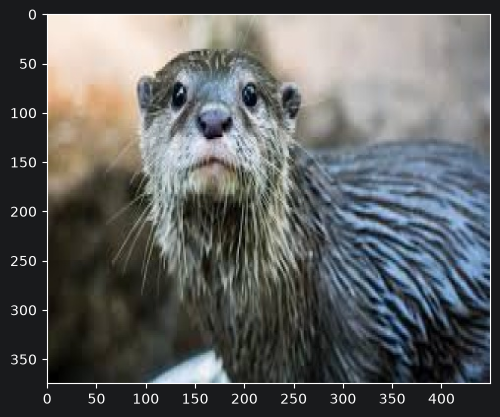

In [62]:
plt.imshow(train_X[0])

In [63]:
train_X.shape

(12260, 375, 450, 3)

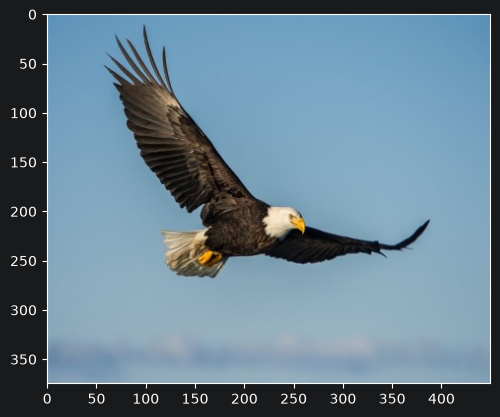

In [64]:
plt.imshow(test_X[0])

In [65]:
test_X.shape

(18673, 375, 450, 3)

In [66]:
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

SEED = 6769
K = 5

y_cols = [c for c in train_y.columns if c not in ("image_id", "fold")]

fold = np.full(len(train_y), -1)                              # -1 = not assigned yet
mskf = MultilabelStratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
for f, (_, val_idx) in enumerate(mskf.split(train_y, train_y[y_cols])):
    fold[val_idx] = f

train_y["fold"] = fold

Path("Data/folds").mkdir(exist_ok=True)
train_y.to_csv("Data/folds/train_folds.csv", index=False)

assert (train_y["fold"] >= 0).all()
print(train_y["fold"].value_counts().sort_index())

fold
0    2452
1    2452
2    2452
3    2452
4    2452
Name: count, dtype: int64


In [67]:
pos_per_fold = train_y.groupby("fold")[y_cols].sum()
print("positives per label per fold:")
print(pos_per_fold)
print("\nshare of each label's positives in each fold:")
print((pos_per_fold / pos_per_fold.sum()).round(3))

zero_targets = pos_per_fold.columns[(pos_per_fold == 0).any(axis=0)]
print(f"\nlabels with 0 positives in at least one fold: {len(zero_targets)} of {len(y_cols)}")

n_labels = train_y[y_cols].sum(axis=1)
print("\nshare of rows by number of active labels, per fold:")
print(pd.crosstab(train_y["fold"], n_labels, normalize="index").round(3))

positives per label per fold:
       Cat   Dog  Moris  Motya  Biatrix
fold                                   
0     1015  1005     11      8        9
1     1016  1005     11      9        8
2     1015  1005     11      8        8
3     1016  1005     11      8        8
4     1015  1005     12      9        8

share of each label's positives in each fold:
      Cat  Dog  Moris  Motya  Biatrix
fold                                 
0     0.2  0.2  0.196  0.190    0.220
1     0.2  0.2  0.196  0.214    0.195
2     0.2  0.2  0.196  0.190    0.195
3     0.2  0.2  0.196  0.190    0.195
4     0.2  0.2  0.214  0.214    0.195

labels with 0 positives in at least one fold: 0 of 5

share of rows by number of active labels, per fold:
col_0      0      1      2      3    4
fold                                  
0      0.176  0.813  0.010  0.001  0.0
1      0.176  0.814  0.008  0.001  0.0
2      0.177  0.814  0.009  0.001  0.0
3      0.176  0.813  0.010  0.000  0.0
4      0.177  0.813  0.009  0.001  0

In [68]:
combo = train_y[y_cols].astype(str).agg("".join, axis=1)
print("order:", y_cols)
print(pd.crosstab(combo, train_y["fold"]))

order: ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']
fold     0    1    2    3    4
row_0                         
00000  432  432  433  432  433
01000  996  997  997  997  997
01001    9    7    7    7    7
10000  998  999  998  997  997
10010    6    6    6    8    6
10100    9    7    8   10    8
10110    2    3    2    0    3
11101    0    1    1    1    1


In [69]:
from sklearn.metrics import f1_score

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", zero_division=0)

def per_class_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average=None, zero_division=0)

def best_thresholds(y_true, y_prob, grid=np.arange(0.02, 0.98, 0.01)):
    th = []
    for j in range(y_true.shape[1]):
        scores = [f1_score(y_true[:, j], y_prob[:, j] >= t, zero_division=0) for t in grid]
        th.append(grid[int(np.argmax(scores))])
    return np.array(th)

def evaluate_oof(y_true, oof_prob, fold):
    fixed = macro_f1(y_true, oof_prob >= 0.5)
    tuned = macro_f1(y_true, oof_prob >= best_thresholds(y_true, oof_prob))   # optimistic

    pred = np.zeros_like(y_true)
    for f in np.unique(fold):
        va = fold == f
        th = best_thresholds(y_true[~va], oof_prob[~va])
        pred[va] = oof_prob[va] >= th
    honest = macro_f1(y_true, pred)
    return {"fixed_0.5": fixed, "tuned_on_oof": tuned, "tuned_honest": honest}

In [70]:
Y = train_y[y_cols].values
rng = np.random.default_rng(SEED)

print("all zeros   :", macro_f1(Y, np.zeros_like(Y)))
print("all ones    :", macro_f1(Y, np.ones_like(Y)))
print("per class (all ones):", dict(zip(y_cols, per_class_f1(Y, np.ones_like(Y)).round(3))))
print("random prior:", macro_f1(Y, (rng.random(Y.shape) < Y.mean(0)).astype(int)))

all zeros   : 0.0
all ones    : 0.2379401853397521
per class (all ones): {'Cat': np.float64(0.586), 'Dog': np.float64(0.581), 'Moris': np.float64(0.009), 'Motya': np.float64(0.007), 'Biatrix': np.float64(0.007)}
random prior: 0.17391603207986556


# Adversarial Validation

In [2]:
import numpy as np, timm, torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

TRAIN_NPY, TEST_NPY = "Data/Arrays/train.npy", "Data/Arrays/test.npy"
MODEL_NAME = "convnext_tiny.fb_in1k"
BATCH = 64

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = timm.create_model(MODEL_NAME, pretrained=True, num_classes=0).to(device).eval()
cfg = timm.data.resolve_data_config({}, model=net)
mean = torch.tensor(cfg["mean"], device=device).view(1, 3, 1, 1)
std = torch.tensor(cfg["std"], device=device).view(1, 3, 1, 1)

@torch.no_grad()
def features(path):
    arr = np.load(path, mmap_mode="r")
    out = []
    for i in range(0, len(arr), BATCH):
        x = torch.from_numpy(np.ascontiguousarray(arr[i:i + BATCH])).to(device).permute(0, 3, 1, 2).float() / 255
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=device.type == "cuda"):
            out.append(net((x - mean) / std).float().cpu())
    return torch.cat(out).numpy()

f_train, f_test = features(TRAIN_NPY), features(TEST_NPY)
X = np.concatenate([f_train, f_test])
y = np.r_[np.zeros(len(f_train)), np.ones(len(f_test))]

clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=2000, class_weight="balanced"))
cv = StratifiedKFold(5, shuffle=True, random_state=42)
p = cross_val_predict(clf, X, y, cv=cv, method="predict_proba")[:, 1]
print(f"adversarial validation AUC (train vs test): {roc_auc_score(y, p):.3f}")


p0 = cross_val_predict(clf, X, np.random.default_rng(0).permutation(y), cv=cv, method="predict_proba")[:, 1]
print(f"control with shuffled labels: {roc_auc_score(y, p0):.3f}")

p_train = p[:len(f_train)]
most_test_like = np.argsort(-p_train)[:12]
print("most test-like train images:", most_test_like)

C:\Users\aboic\IdeaProjects\language_model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\aboic\AppData\Local\Temp\ipykernel_4328\473880282.py:23: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  x = torch.from_numpy(np.ascontiguousarray(arr[i:i + BATCH])).to(device).permute(0, 3, 1, 2).float() / 255


adversarial validation AUC (train vs test): 0.508
control with shuffled labels: 0.504
most test-like train images: [ 3421   744  2401   160  8748 10949   977  2553  5706 10506   847  2215]
